# Customer Churn Prediction

> **Sample data disclaimer:** This notebook uses sample data, not the original business data. Cohort sizes, churn rates, model metrics, and customer rankings are specific to this sample and may differ with the original data.

The business defines an inactive customer as someone with no purchase for more than 90 days. This analysis builds a 90-day forward outcome for customers who purchased during the 90 days before each scoring date.


## 1. Load and Prepare the Sample Data

The project sample tables use the shared English column schema. Paths work when this notebook is launched from either the repository root or the `notebooks` directory.


In [1]:
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.tree import DecisionTreeClassifier

import sys
repo_root = Path.cwd()
if not (repo_root / "data" / "sample").is_dir():
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root))

from src.data import clean_tables, load_raw_tables

sample_dir = repo_root / "data" / "sample"
output_dir = repo_root / "charts_and_figures" / "churn_recommendation"
output_dir.mkdir(parents=True, exist_ok=True)

customers_df, products_df, sales_df = load_raw_tables(sample_dir)
customers_df, products_df, sales_df = clean_tables(
    customers_df, products_df, sales_df
)
sales_df = sales_df.dropna(
    subset=["SALE_ID", "SALE_DATE", "CUSTOMER_ID", "PRODUCT_ID", "SALE_CATEGORY"]
).copy()
sales_df = sales_df.loc[sales_df["QUANTITY"].fillna(0).ge(0)].copy()
sales_df["SALE_CATEGORY"] = sales_df["SALE_CATEGORY"].str.upper().str.strip()
sales_df["ORDER_KEY"] = (
    sales_df["BRANCH"].astype("string").fillna("UNKNOWN")
    + "_"
    + sales_df["SALE_ID"].astype("string")
)

print(f"Customers in table: {customers_df['CUSTOMER_ID'].nunique():,}")
print(f"Sales line items: {len(sales_df):,}")
print(f"Unique customers with sales: {sales_df['CUSTOMER_ID'].nunique():,}")
print(f"Observed sales period: {sales_df['SALE_DATE'].min().date()} to {sales_df['SALE_DATE'].max().date()}")
print("Sales categories:", ", ".join(sorted(sales_df["SALE_CATEGORY"].dropna().unique())))

Customers in table: 5,000
Sales line items: 129,032
Unique customers with sales: 4,998
Observed sales period: 2020-01-02 to 2021-10-26
Sales categories: CLINIC, DIGITAL, E-COMMERCE, GROOMING, STORE


Matplotlib is building the font cache; this may take a moment.


## 2. Define Scoring Cohorts and the Outcome

For a scoring date, eligible customers must have purchased in the prior 90 days. The churn outcome is 1 when the customer makes no purchase during the following 91 calendar dates. This makes the outcome consistent with inactivity of **more than** 90 days. Each cohort is accepted only when its complete outcome window is present in the sample.

The January cohort is used to fit candidate models, April is a forward validation cohort, and July is the final holdout. The label windows finish before the next cohort begins, so no future cohort outcomes enter earlier model training.


In [2]:
LOOKBACK_DAYS = 90
FOLLOWUP_DAYS = 91
RANDOM_SEED = 10

CATEGORY_FEATURES = {
    category: f"CATEGORY_{category.replace('-', '').replace(' ', '_')}_ORDERS"
    for category in sorted(sales_df["SALE_CATEGORY"].dropna().unique())
}

def build_customer_cohort(reference_date, sales, category_features):
    reference_date = pd.Timestamp(reference_date).normalize()
    label_window_end = reference_date + pd.Timedelta(days=FOLLOWUP_DAYS)
    observed_through = sales["SALE_DATE"].max().normalize()
    if observed_through < label_window_end - pd.Timedelta(days=1):
        raise ValueError(
            f"Incomplete follow-up for {reference_date.date()}: "
            f"need data through {(label_window_end - pd.Timedelta(days=1)).date()}, "
            f"but sample ends on {observed_through.date()}."
        )

    lookback_start = reference_date - pd.Timedelta(days=LOOKBACK_DAYS)
    recent_customer_ids = sales.loc[
        sales["SALE_DATE"].between(lookback_start, reference_date, inclusive="left"),
        "CUSTOMER_ID",
    ].dropna().unique()
    if len(recent_customer_ids) == 0:
        raise ValueError(f"No eligible customers for {reference_date.date()}.")

    history = sales.loc[
        sales["SALE_DATE"].lt(reference_date)
        & sales["CUSTOMER_ID"].isin(recent_customer_ids)
    ].copy()
    customer_features = history.groupby("CUSTOMER_ID").agg(
        ORDER_COUNT=("ORDER_KEY", "nunique"),
        PRODUCT_VARIETY=("PRODUCT_ID", "nunique"),
        TOTAL_QUANTITY=("QUANTITY", "sum"),
        FIRST_OBSERVED_SALE=("SALE_DATE", "min"),
        LAST_SALE=("SALE_DATE", "max"),
    )
    customer_features["RECENCY_DAYS"] = (
        reference_date - customer_features["LAST_SALE"]
    ).dt.days
    customer_features["OBSERVED_TENURE_DAYS"] = (
        customer_features["LAST_SALE"] - customer_features["FIRST_OBSERVED_SALE"]
    ).dt.days
    interval_count = customer_features["ORDER_COUNT"].sub(1).clip(lower=1)
    customer_features["MEAN_DAYS_BETWEEN_ORDERS"] = (
        customer_features["OBSERVED_TENURE_DAYS"] / interval_count
    )

    category_order_counts = (
        history.drop_duplicates(["CUSTOMER_ID", "ORDER_KEY", "SALE_CATEGORY"])
        .groupby(["CUSTOMER_ID", "SALE_CATEGORY"])["ORDER_KEY"]
        .nunique()
        .unstack(fill_value=0)
        .rename(columns=category_features)
    )
    customer_features = customer_features.join(category_order_counts, how="left")
    customer_features = customer_features.drop(
        columns=["FIRST_OBSERVED_SALE", "LAST_SALE"], errors="ignore"
    )
    customer_features = customer_features.reindex(
        columns=[
            "ORDER_COUNT", "PRODUCT_VARIETY", "TOTAL_QUANTITY",
            "RECENCY_DAYS", "OBSERVED_TENURE_DAYS", "MEAN_DAYS_BETWEEN_ORDERS",
            *category_features.values(),
        ],
        fill_value=0,
    ).fillna(0)

    future_purchases = sales.loc[
        sales["SALE_DATE"].ge(reference_date)
        & sales["SALE_DATE"].lt(label_window_end),
        "CUSTOMER_ID",
    ].dropna().unique()
    customer_features["CHURN_FLAG"] = (
        ~customer_features.index.isin(future_purchases)
    ).astype(int)
    customer_features = customer_features.reset_index()
    customer_features["REFERENCE_DATE"] = reference_date
    return customer_features

cohort_dates = {
    "train": "2021-01-01",
    "validation": "2021-04-02",
    "holdout": "2021-07-02",
}
cohorts = {
    name: build_customer_cohort(date, sales_df, CATEGORY_FEATURES)
    for name, date in cohort_dates.items()
}
for name, cohort in cohorts.items():
    print(
        f"{name.title():<10} reference={cohort['REFERENCE_DATE'].iloc[0].date()} "
        f"customers={len(cohort):,} churn_rate={cohort['CHURN_FLAG'].mean():.1%}"
    )

Train      reference=2021-01-01 customers=3,658 churn_rate=27.0%
Validation reference=2021-04-02 customers=3,477 churn_rate=26.9%
Holdout    reference=2021-07-02 customers=3,499 churn_rate=26.2%


## 3. Fit Candidate Models on the Training Cohort

The models are fitted only on the January cohort. April is kept separate for model selection and decision-threshold selection. A prior-probability baseline is included so the classifiers are compared with a simple benchmark.


In [3]:
TARGET = "CHURN_FLAG"
ID_COLUMNS = ["CUSTOMER_ID", "REFERENCE_DATE"]
FEATURE_COLUMNS = [
    column for column in cohorts["train"].columns
    if column not in ID_COLUMNS + [TARGET]
]

def get_xy(cohort):
    return cohort[FEATURE_COLUMNS].astype(float), cohort[TARGET].astype(int)

X_train, y_train = get_xy(cohorts["train"])
X_validation, y_validation = get_xy(cohorts["validation"])

model_candidates = {
    "Decision tree": DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=40, class_weight="balanced",
        random_state=RANDOM_SEED,
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=200, max_depth=10, min_samples_leaf=20,
        class_weight="balanced_subsample", n_jobs=-1,
        random_state=RANDOM_SEED,
    ),
}
baseline_model = DummyClassifier(strategy="prior")
baseline_model.fit(X_train, y_train)

validation_scores = {}
for model_name, model in model_candidates.items():
    model.fit(X_train, y_train)
    validation_scores[model_name] = model.predict_proba(X_validation)[:, 1]

def average_precision(y_true, scores):
    return average_precision_score(y_true, scores)

validation_summary = pd.DataFrame(
    {
        model_name: {
            "ROC AUC": roc_auc_score(y_validation, scores),
            "Average precision": average_precision(y_validation, scores),
        }
        for model_name, scores in validation_scores.items()
    }
).T
baseline_validation_scores = baseline_model.predict_proba(X_validation)[:, 1]
validation_summary.loc["Prior baseline"] = [
    roc_auc_score(y_validation, baseline_validation_scores),
    average_precision(y_validation, baseline_validation_scores),
]
print(validation_summary.round(3).to_string())

selected_model_name = validation_summary.drop(index="Prior baseline")[
    "Average precision"
].idxmax()
selected_model = model_candidates[selected_model_name]
selected_validation_scores = validation_scores[selected_model_name]
precision_values, recall_values, threshold_values = precision_recall_curve(
    y_validation, selected_validation_scores
)
f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-12)
)
selected_threshold = (
    float(threshold_values[int(np.argmax(f1_values))])
    if len(threshold_values) else 0.5
)
print(f"Selected model by April average precision: {selected_model_name}")
print(f"Decision threshold selected on April validation: {selected_threshold:.3f}")

                ROC AUC  Average precision
Decision tree     0.655              0.351
Random forest     0.654              0.344
Prior baseline    0.500              0.269
Selected model by April average precision: Decision tree
Decision threshold selected on April validation: 0.381


## 4. Final Holdout Evaluation

After model and threshold selection on April, refit the selected classifier on the January and April cohorts. July is used once as the final forward holdout. Metrics and rankings below describe only this sample.


In [4]:
development_data = pd.concat(
    [cohorts["train"], cohorts["validation"]], ignore_index=True
)
X_development, y_development = get_xy(development_data)
X_holdout, y_holdout = get_xy(cohorts["holdout"])
final_model = clone(selected_model)
final_model.fit(X_development, y_development)
holdout_scores = final_model.predict_proba(X_holdout)[:, 1]
holdout_predictions = (holdout_scores >= selected_threshold).astype(int)

def summarize_scores(y_true, scores, threshold):
    predicted = (scores >= threshold).astype(int)
    top_count = max(1, math.ceil(0.10 * len(scores)))
    top_indices = np.argsort(scores)[::-1][:top_count]
    prevalence = float(np.mean(y_true))
    top_precision = float(np.mean(np.asarray(y_true)[top_indices]))
    return {
        "Customers": len(y_true),
        "Churn prevalence": prevalence,
        "ROC AUC": roc_auc_score(y_true, scores),
        "Average precision": average_precision_score(y_true, scores),
        "Threshold": threshold,
        "Precision at threshold": float(np.mean(np.asarray(y_true)[predicted == 1])) if predicted.sum() else 0.0,
        "Recall at threshold": float(np.sum((predicted == 1) & (np.asarray(y_true) == 1)) / max(1, np.sum(np.asarray(y_true) == 1))),
        "F1 at threshold": float(2 * np.sum((predicted == 1) & (np.asarray(y_true) == 1)) / max(1, predicted.sum() + np.sum(np.asarray(y_true) == 1))),
        "Top 10% precision": top_precision,
        "Top 10% recall": float(np.sum(np.asarray(y_true)[top_indices]) / max(1, np.sum(np.asarray(y_true) == 1))),
        "Top 10% lift": top_precision / prevalence if prevalence else 0.0,
    }

holdout_summary = pd.DataFrame(
    [
        summarize_scores(y_holdout, holdout_scores, selected_threshold),
        summarize_scores(
            y_holdout,
            DummyClassifier(strategy="prior").fit(X_development, y_development).predict_proba(X_holdout)[:, 1],
            0.5,
        ),
    ],
    index=[selected_model_name, "Prior baseline"],
)
print(holdout_summary.round(3).to_string())
print("\nClassification report at the validation-selected threshold:")
print(classification_report(y_holdout, holdout_predictions, zero_division=0))
print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_holdout, holdout_predictions))

                Customers  Churn prevalence  ROC AUC  Average precision  Threshold  Precision at threshold  Recall at threshold  F1 at threshold  Top 10% precision  Top 10% recall  Top 10% lift
Decision tree        3499             0.262    0.669              0.364      0.381                   0.341                0.838            0.485              0.417           0.159         1.592
Prior baseline       3499             0.262    0.500              0.262      0.500                   0.000                0.000            0.000              0.249           0.095         0.948

Classification report at the validation-selected threshold:
              precision    recall  f1-score   support

           0       0.88      0.43      0.57      2582
           1       0.34      0.84      0.49       917

    accuracy                           0.53      3499
   macro avg       0.61      0.63      0.53      3499
weighted avg       0.74      0.53      0.55      3499

Confusion matrix (rows=true, c

## 5. Holdout Ranking and Outputs

For retention use, a ranked list may be more useful than a single probability cutoff. The top-decile precision, recall, and lift show how the highest-risk 10% of the holdout cohort compare with its overall churn rate.


In [5]:
holdout_output = cohorts["holdout"][["CUSTOMER_ID", "REFERENCE_DATE", TARGET]].copy()
holdout_output["CHURN_PROBABILITY"] = holdout_scores
holdout_output = holdout_output.sort_values(
    "CHURN_PROBABILITY", ascending=False
).reset_index(drop=True)
holdout_output["RISK_RANK"] = np.arange(1, len(holdout_output) + 1)
holdout_output["RISK_DECILE"] = np.minimum(
    10, np.ceil(holdout_output["RISK_RANK"] * 10 / len(holdout_output))
).astype(int)
holdout_output["TOP_DECILE_TARGET"] = holdout_output["RISK_DECILE"].eq(1)

lift_table = holdout_output.groupby("RISK_DECILE").agg(
    CUSTOMERS=("CUSTOMER_ID", "size"),
    CHURN_RATE=(TARGET, "mean"),
    MEAN_CHURN_PROBABILITY=("CHURN_PROBABILITY", "mean"),
).reset_index()
lift_table["LIFT_VS_COHORT"] = (
    lift_table["CHURN_RATE"] / holdout_output[TARGET].mean()
)

metrics_path = output_dir / "holdout_metrics.csv"
predictions_path = output_dir / "holdout_churn_scores.csv"
lift_path = output_dir / "holdout_lift_by_decile.csv"
holdout_summary.to_csv(metrics_path)
holdout_output.to_csv(predictions_path, index=False)
lift_table.to_csv(lift_path, index=False)
print("\nSaved outputs:")
for output_path in [metrics_path, predictions_path, lift_path]:
    print(output_path.relative_to(repo_root))
print("\nLift by risk decile:")
print(lift_table.round(3).to_string(index=False))


Saved outputs:
charts_and_figures/churn_recommendation/holdout_metrics.csv
charts_and_figures/churn_recommendation/holdout_churn_scores.csv
charts_and_figures/churn_recommendation/holdout_lift_by_decile.csv

Lift by risk decile:
 RISK_DECILE  CUSTOMERS  CHURN_RATE  MEAN_CHURN_PROBABILITY  LIFT_VS_COHORT
           1        349       0.407                   0.700           1.553
           2        350       0.371                   0.617           1.417
           3        350       0.343                   0.596           1.308
           4        350       0.366                   0.594           1.395
           5        350       0.291                   0.497           1.112
           6        350       0.289                   0.451           1.101
           7        350       0.237                   0.371           0.905
           8        350       0.146                   0.306           0.556
           9        350       0.157                   0.160           0.600
          

Saved charts_and_figures/churn_recommendation/holdout_roc_curve.png


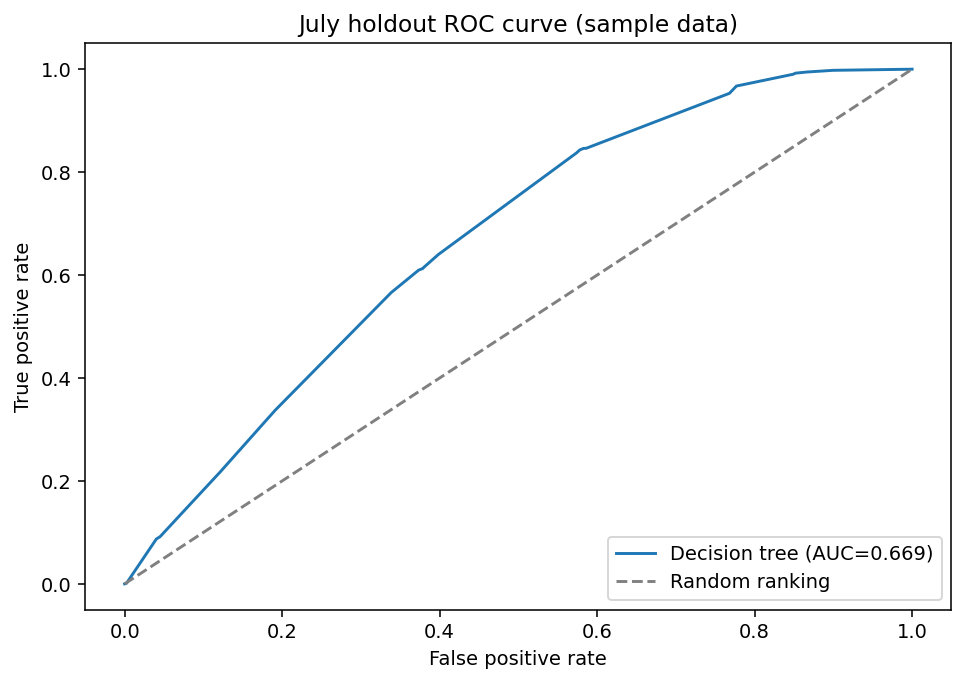

In [6]:
fpr, tpr, _ = roc_curve(y_holdout, holdout_scores)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"{selected_model_name} (AUC={holdout_summary.loc[selected_model_name, 'ROC AUC']:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random ranking")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("July holdout ROC curve (sample data)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(output_dir / "holdout_roc_curve.png", dpi=140)
print(f"Saved {output_dir.relative_to(repo_root) / 'holdout_roc_curve.png'}")

## Interpretation

This is a sample-data demonstration. The selected model, churn prevalence, scores, and customer ranking can change with the original business data. Before using these results for campaigns, validate the churn definition and scoring cadence with the business and assess campaign capacity and outcomes.
